# Porto Seguro's Safe Driver Prediction

## Il problema
Porto Seguro è una delle maggiori compagnie di assicurazione auto del Brasile. Se le previsioni sui sinistri sono imprecise, i buoni guidatori pagano un premio troppo alto e i cattivi guidatori uno troppo basso.

**Obiettivo:** costruire un modello che stimi la **probabilità che un assicurato apra una richiesta di risarcimento** (un sinistro) nell'anno successivo. Una stima migliore del rischio permette di fissare premi più equi.

- **Classificazione binaria**: il target vale 1 se l'assicurato ha aperto un sinistro e 0 altrimenti.
- Devo restituire una  **probabilità** per ogni assicurato del test set.

## I dati
| File | Righe | Contenuto |
|---|---|---|
| `train.csv` | 595 212 | `id`, `target` e 57 feature |
| `test.csv` | 892 816 | `id` e le stesse 57 feature, **senza** `target` |

Le feature sono **anonimizzate**: non so cosa rappresentino, ma il nome segue lo schema `ps_<gruppo>_<numero>_<tipo>`.
- **Gruppo**: `ind`, `reg`, `car`, `calc`. La competizione dice solo che le variabili dello stesso gruppo sono simili tra loro. L'interpretazione più diffusa è individuo, regione, veicolo e variabili calcolate.
- **Tipo**: il suffisso `_bin` indica una variabile binaria, `_cat` una categorica; senza suffisso la variabile è numerica (continua o ordinale).
- **I valori mancanti sono codificati come `-1`**, non come `NaN`.

## La metrica
La competizione usa il **Gini normalizzato**, che equivale a `2 · AUC − 1`.
- Misura quanto bene il modello **ordina** gli assicurati, mettendo i più rischiosi in cima. Il valore assoluto delle probabilità non conta, conta solo l'ordine.
- Vale 0 per un modello casuale e 1 per uno perfetto.

## Piano di lavoro
1. **EDA**: distribuzione del target, valori mancanti, tipi di variabili, relazione tra ogni variabile e il tasso di sinistri.
2. **Validation**: cross-validation stratificata a 5 fold, per stimare il Gini in modo affidabile e confrontare le scelte sugli stessi fold.
3. **Miglioramento del modello**: selezione delle feature, parametri di LightGBM, feature engineering.
4. **Submission**: previsioni sul test nel formato `id, target`.

In [61]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df_train = pd.read_csv("data/train.csv")
df_test  = pd.read_csv("data/test.csv")

## Exploratory Data Analysis (EDA)

In [62]:
print(f"Training dataframe\nNumber of rows: {df_train.shape[0]}, Number of columns: {df_train.shape[1]}")
print(f"Test dataframe\nNumber of rows: {df_test.shape[0]}, Number of columns: {df_test.shape[1]}")

Training dataframe
Number of rows: 595212, Number of columns: 59
Test dataframe
Number of rows: 892816, Number of columns: 58


In [63]:
df_train.head()

,id,target,ps_ind_01,ps_ind_02_cat,ps_ind_03,ps_ind_04_cat,ps_ind_05_cat,ps_ind_06_bin,ps_ind_07_bin,ps_ind_08_bin,...,ps_calc_11,ps_calc_12,ps_calc_13,ps_calc_14,ps_calc_15_bin,ps_calc_16_bin,ps_calc_17_bin,ps_calc_18_bin,ps_calc_19_bin,ps_calc_20_bin
0,7,0,2,2,5,1,0,0,1,0,...,9,1,5,8,0,1,1,0,0,1
1,9,0,1,1,7,0,0,0,0,1,...,3,1,1,9,0,1,1,0,1,0
2,13,0,5,4,9,1,0,0,0,1,...,4,2,7,7,0,1,1,0,1,0
3,16,0,0,1,2,0,0,1,0,0,...,2,2,4,9,0,0,0,0,0,0
4,17,0,0,2,0,1,0,1,0,0,...,3,1,1,3,0,0,0,1,1,0


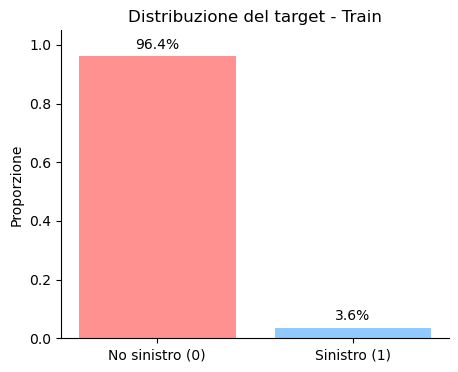

In [64]:
# Proporzione di positivi 

prop_train = df_train["target"].value_counts(normalize=True).sort_index()

fig, ax = plt.subplots(figsize=(5,4))
bars = ax.bar(prop_train.index.astype(str), prop_train.values, color =["#ff9191", "#91caff"])
ax.bar_label(bars, labels=[f"{p:.1%}" for p in prop_train.values], padding=3)


ax.set_xticks([0, 1], ["No sinistro (0)", "Sinistro (1)"])
ax.set_ylabel("Proporzione")
ax.set_ylim(0, 1.05)
ax.set_title("Distribuzione del target - Train")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

- Classi molto **sbilanciate**, solo il 3,6% dei clienti assicurati riporta un sinistro.

In [65]:
# Tabella dei missing data --- quali variabili hanno missing data

missing = (df_train == -1).sum() # mi dice per ogni variabile quanti missing ci sono (dataFrame costituito da 0/False e 1/True, e sommo per colonna)
missing = missing[missing>0].sort_values(ascending=False) # voglio solo le variabili che hanno i missing e ordino in modo discendente (dalla feature con più missing in giù)
# missing è una series -> la voglio trasformare in un DataFrame


missing_df = pd.DataFrame({
            "n_missing": missing,
            "perc_missing": (missing / len(df_train) * 100).round(4)
            })
missing_df

,n_missing,perc_missing
ps_car_03_cat,411231,69.0898
ps_car_05_cat,266551,44.7825
ps_reg_03,107772,18.1065
ps_car_14,42620,7.1605
ps_car_07_cat,11489,1.9302
ps_ind_05_cat,5809,0.9760
ps_car_09_cat,569,0.0956
ps_ind_02_cat,216,0.0363
ps_car_01_cat,107,0.0180
ps_ind_04_cat,83,0.0139


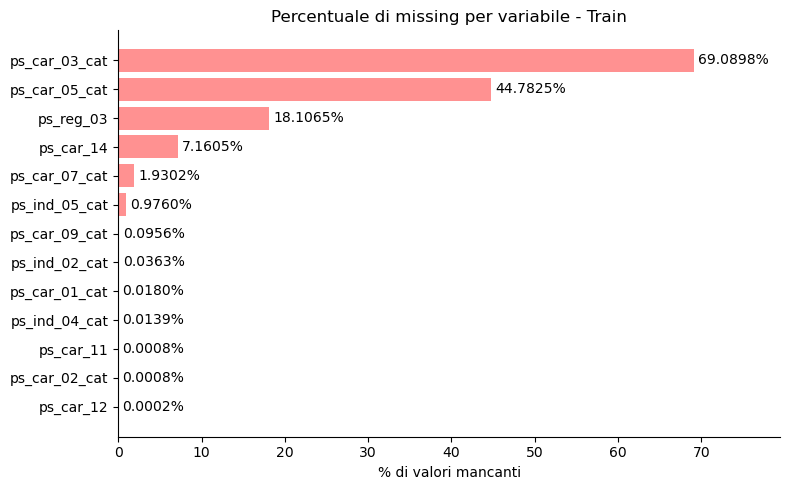

In [66]:
perc = (df_train == -1).mean().mul(100)
perc = perc[perc > 0].sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(perc.index, perc.values, color="#ff9191")
ax.bar_label(bars, labels=[f"{p:.4f}%" for p in perc.values], padding=3)

ax.set_xlabel("% di valori mancanti")
ax.set_title("Percentuale di missing per variabile - Train")
ax.set_xlim(0, perc.max() * 1.15)
ax.spines[["top", "right"]].set_visible(False) # nasconde il bordo superiore e quello destro
fig.tight_layout()
plt.show()

- 13 features presentano dei missing, ma solo 6 di queste superiori, o quasi, all'1%
- Avere l'1% delle osservazioni missing vuol dire comunque avere circa 5900 obs mancanti

In [67]:
# per ciascun gruppo, quante variabili ci sono e di che tipo
features = [c for c in df_train.columns if c.startswith("ps_")]

meta = pd.DataFrame({"variabile": features})
meta["gruppo"] = meta["variabile"].str.split("_").str[1] # creo la colonna gruppo, splittando dove si presenta un _ e lasciando solo il secondo elemento (cella 1)
meta["tipo"]   = meta["variabile"].str.split("_").str[-1] # avrei potuto scrivere .str[2]
meta["tipo"]   = meta["tipo"].where(meta["tipo"].isin(["bin","cat"]), "altro") # lascia il valore dove la condizione è vera e mette "altro" dove è falsa

pd.crosstab(meta["gruppo"], meta["tipo"], margins=True, margins_name="Totale") # conta le combinazioni gruppo x tipo, margins=True aggiunge i totali di riga e di colonna

tipo,altro,bin,cat,Totale
gruppo,,,,
calc,14,6,0,20
car,5,0,11,16
ind,4,11,3,18
reg,3,0,0,3
Totale,26,17,14,57


In [68]:
def tasso_positivi(df, var, max_valori=20, n_bin=10):
    x = df[var]
    miss = x == -1
    x_ok = x[~miss]

    if x_ok.nunique() > max_valori:                   # quantili solo sui non mancanti
        x_ok = pd.qcut(x_ok, q=n_bin, duplicates="drop")

    t = df.loc[~miss].groupby(x_ok, observed=True)["target"].agg(tasso="mean", n="size")
    t.index = t.index.astype(str)

    if miss.any():                                    # aggiungo la barra dei mancanti in fondo
        t.loc["missing"] = [df.loc[miss, "target"].mean(), miss.sum()]
    return t


In [69]:
def formato_n(n):
    return f"{n/1000:.1f}k" if n >= 1000 else f"{int(n)}"


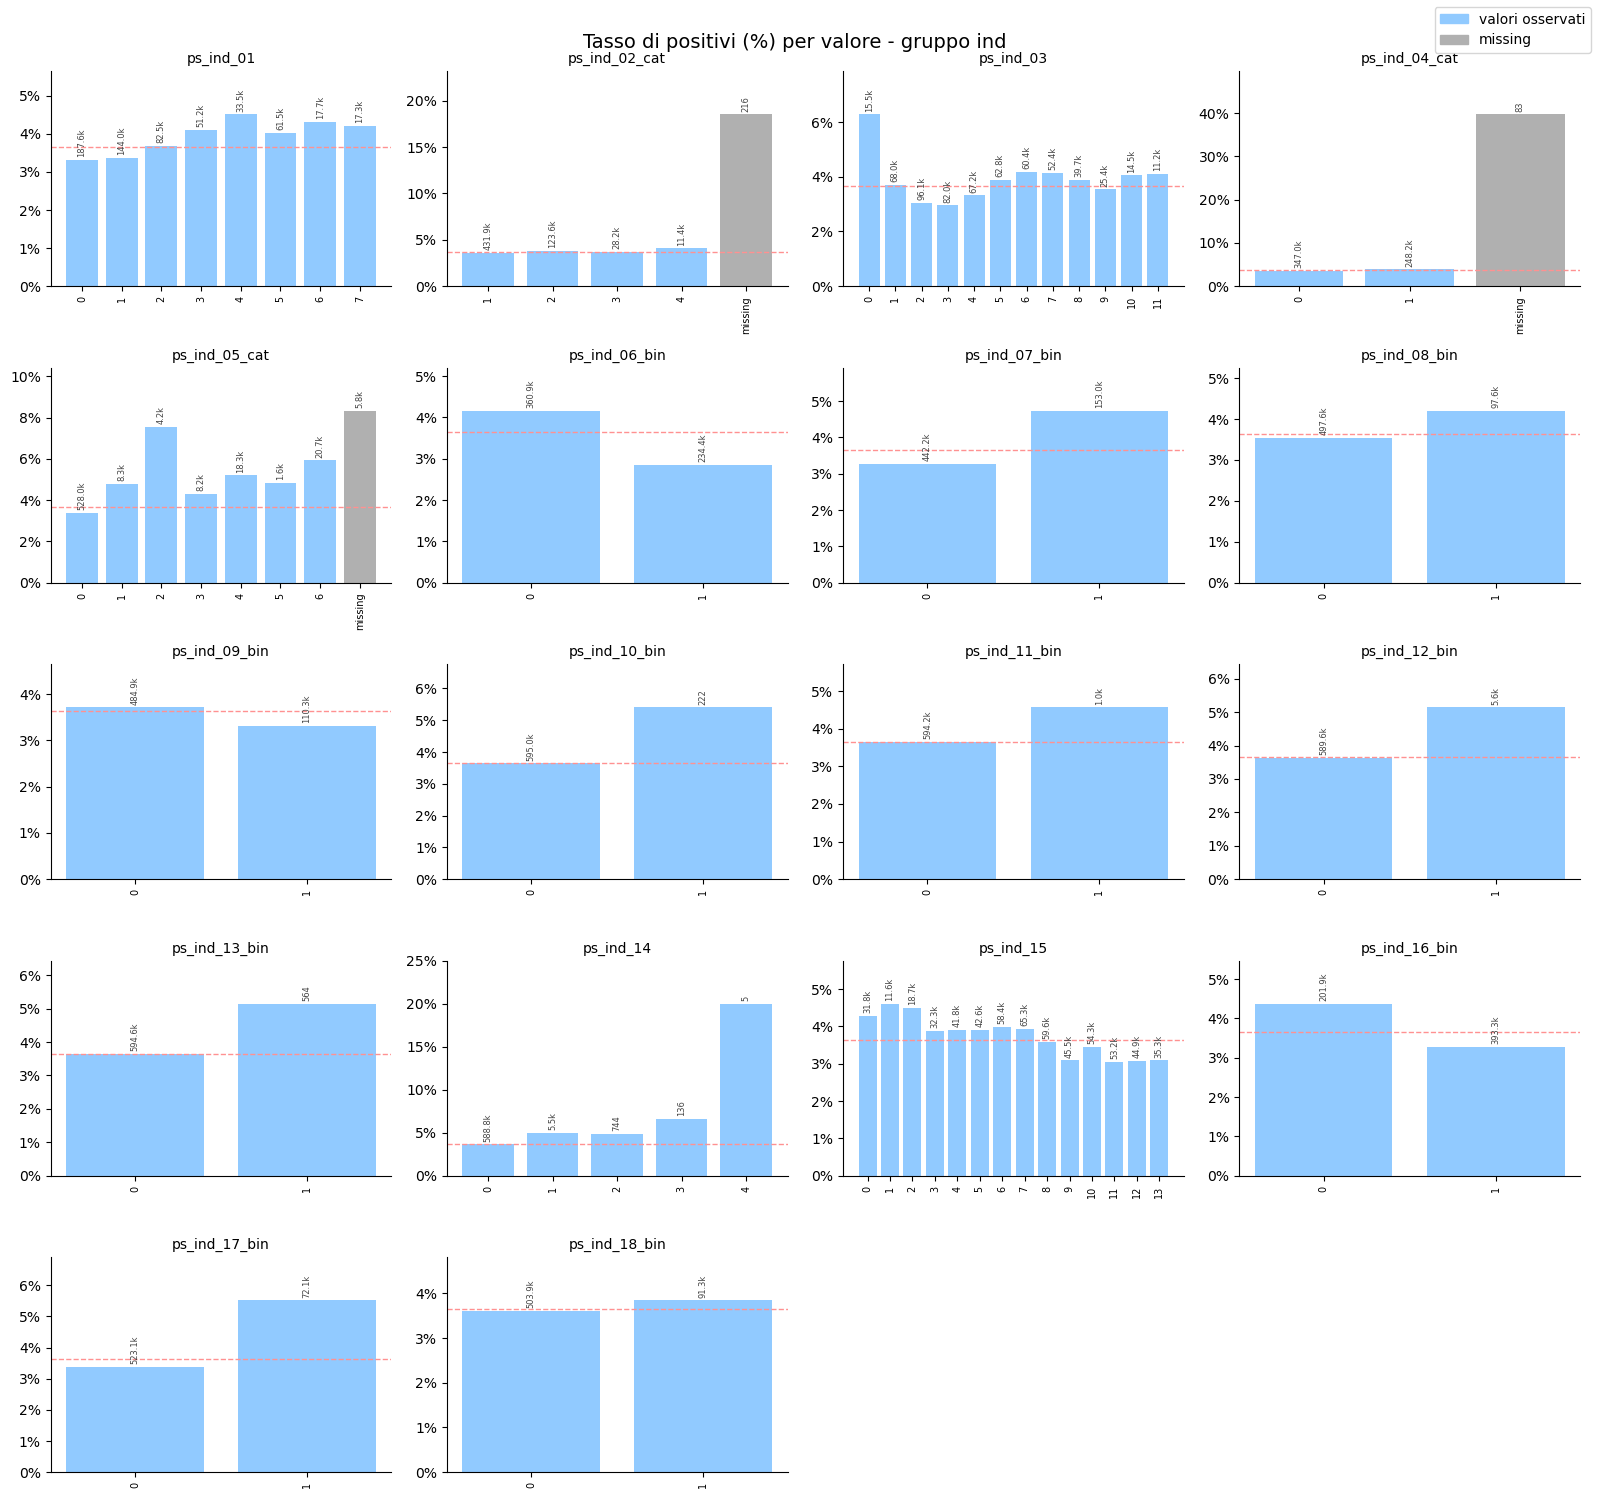

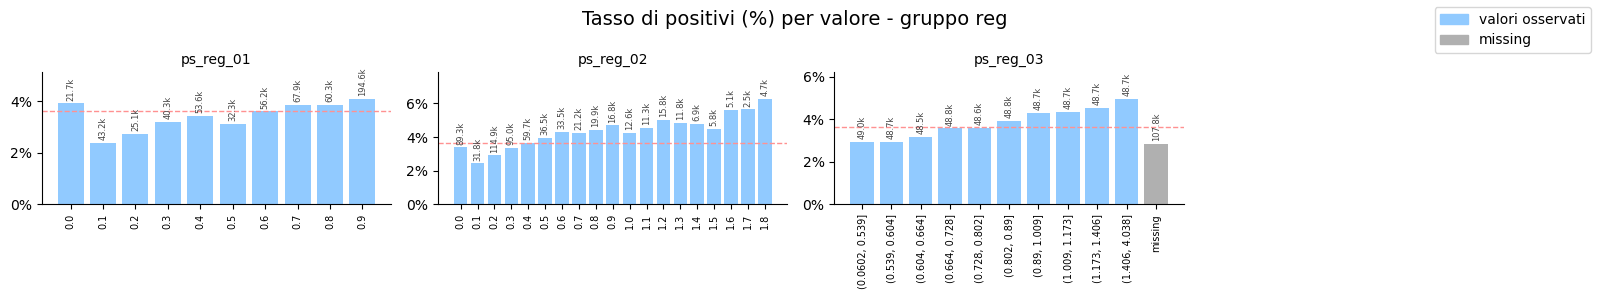

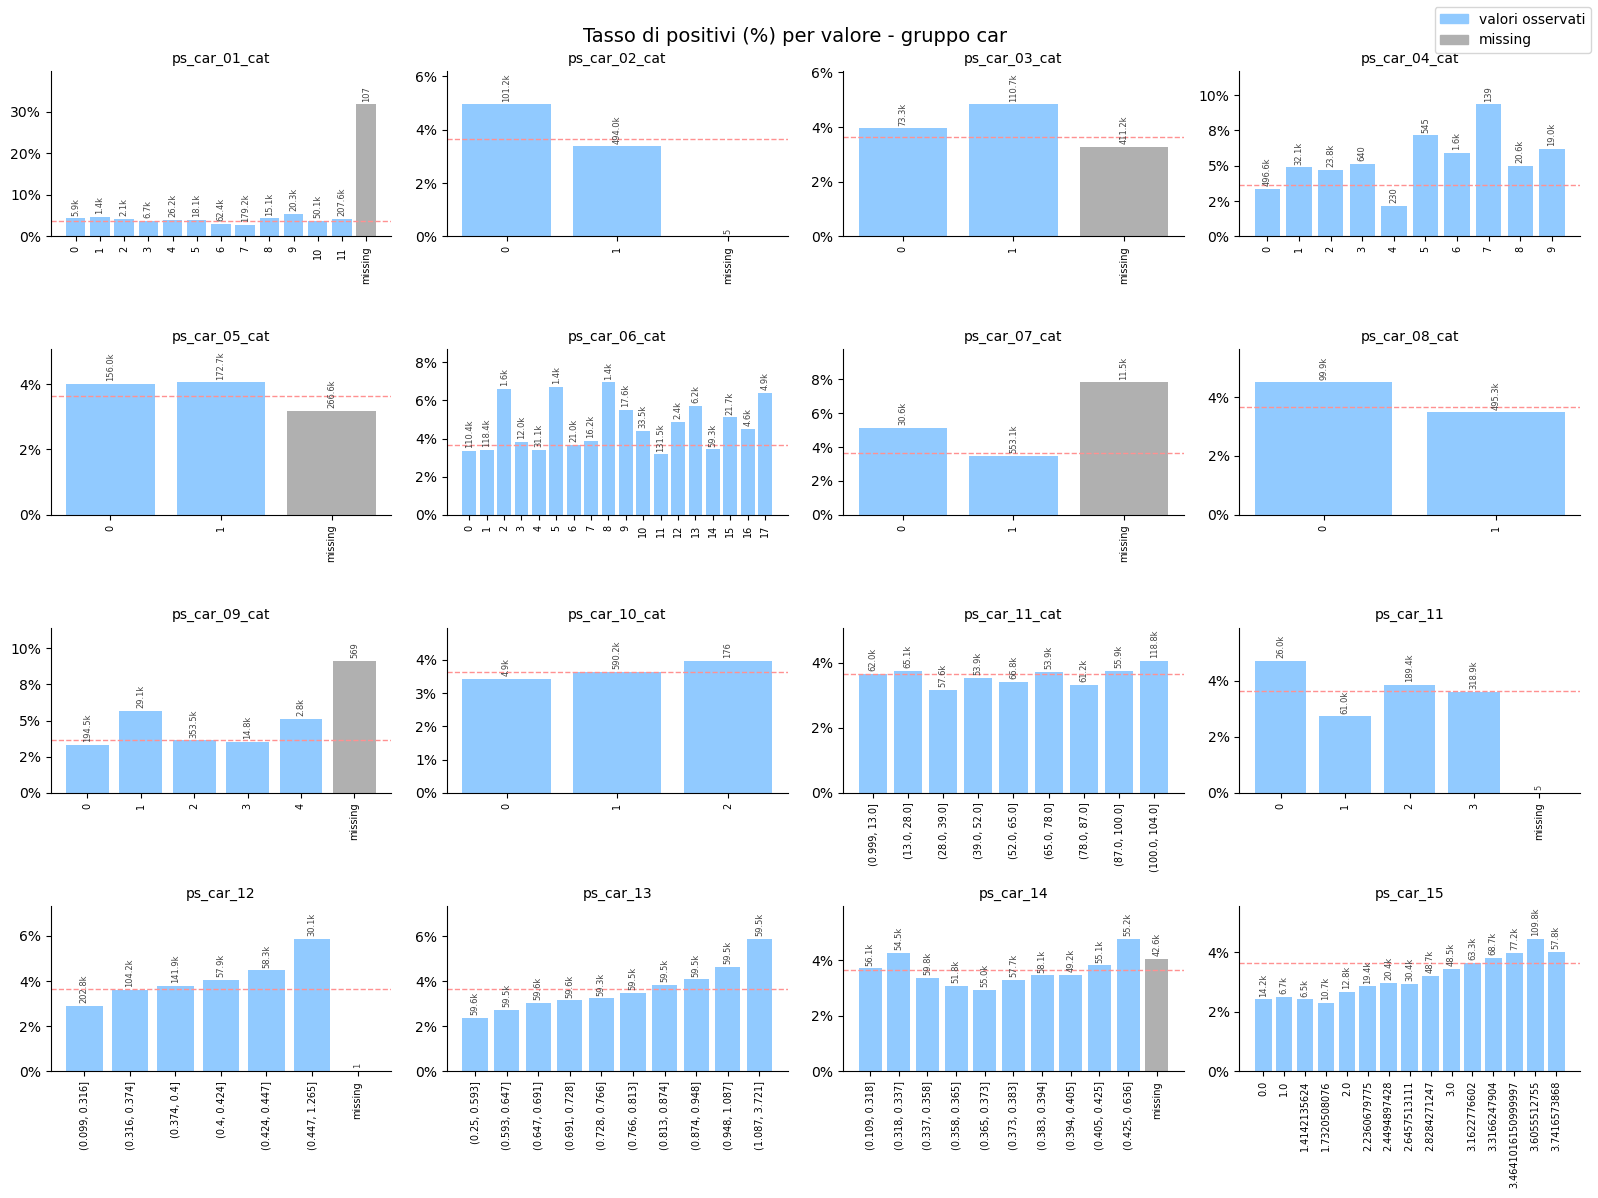

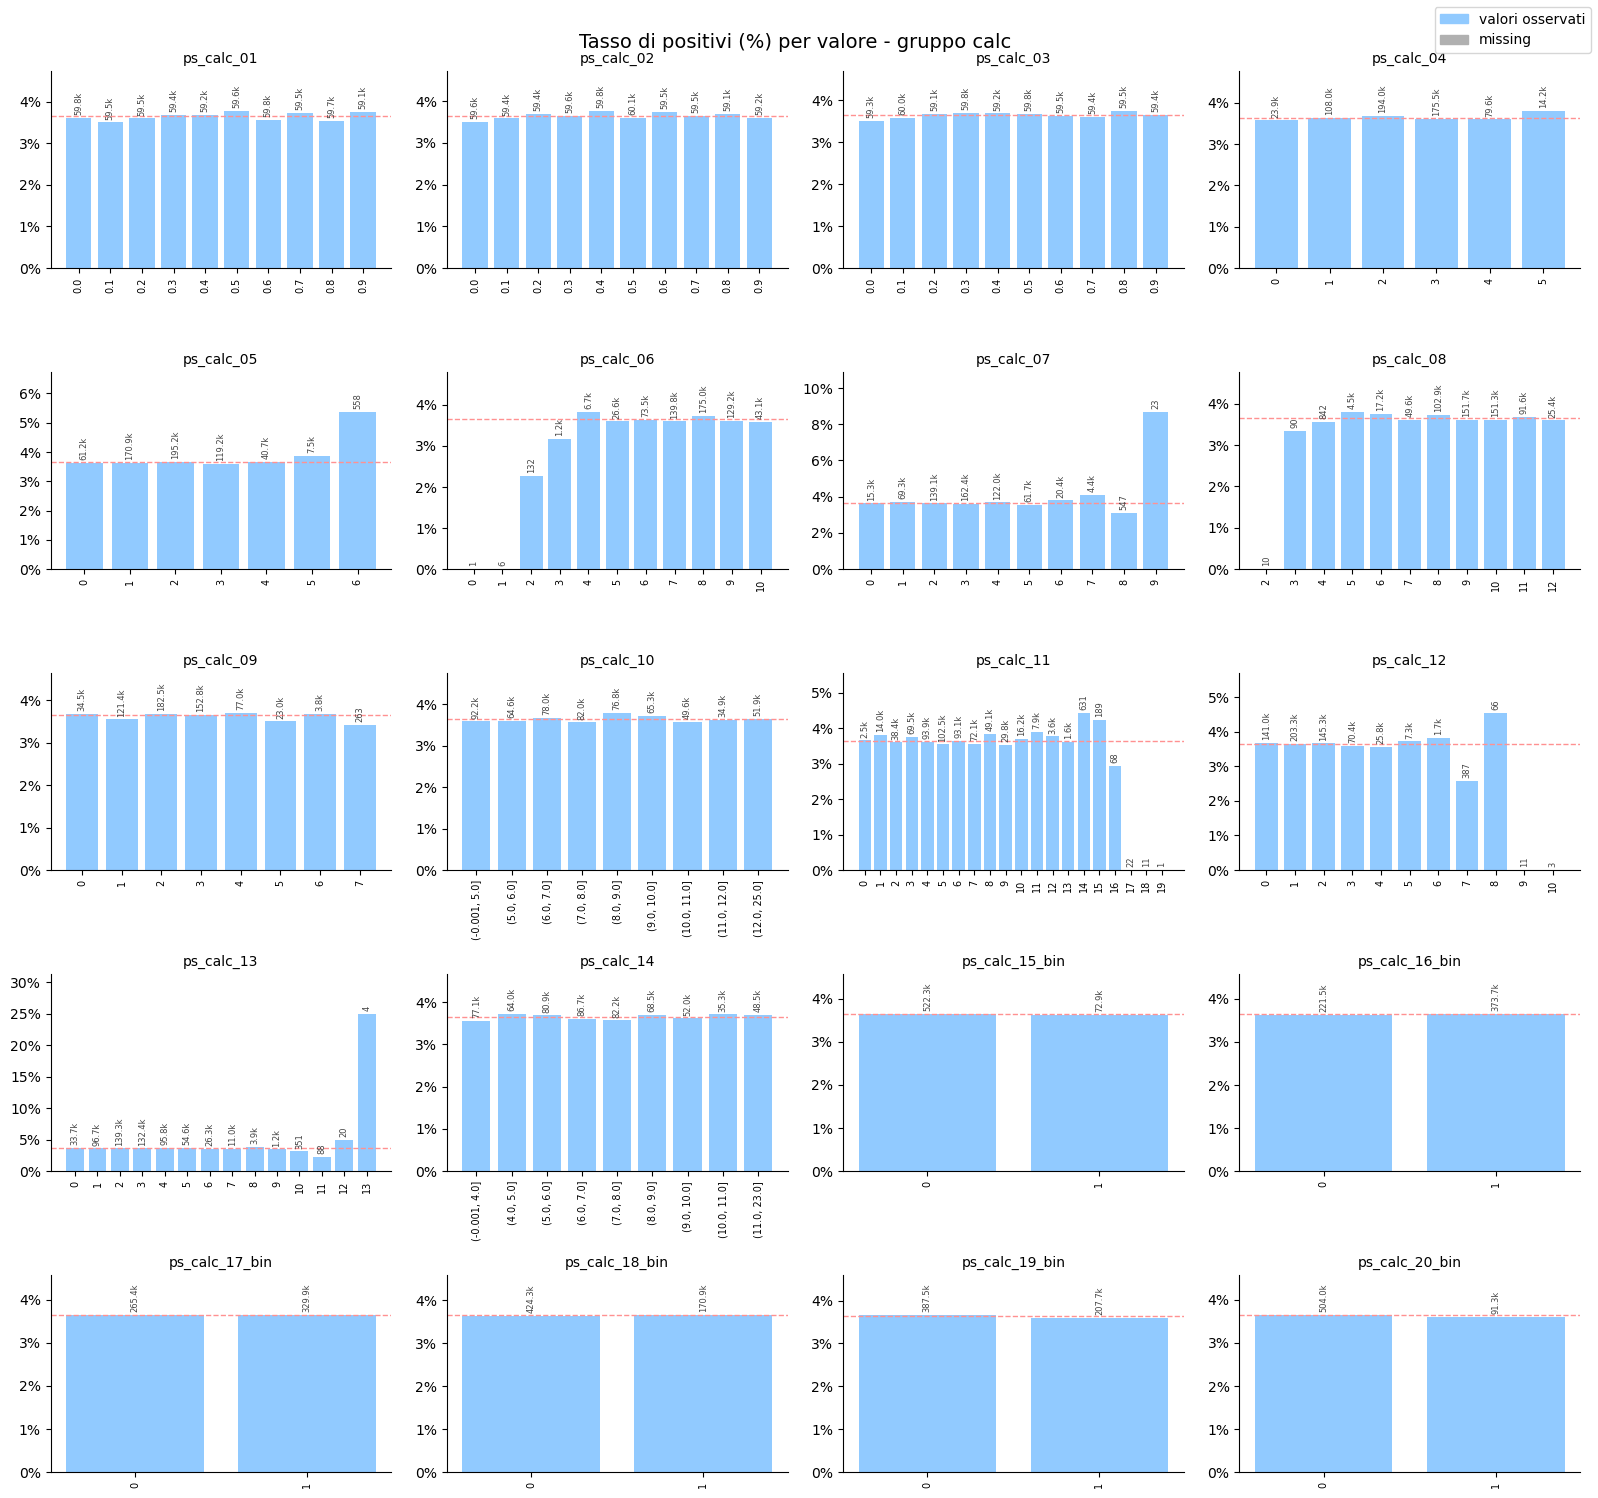

In [70]:
# per ogni gruppo vediamo come cambia il tasso di positivi al variare dei suoi valori
from matplotlib.ticker import PercentFormatter
from matplotlib.patches import Patch

COL_OSS = "#91caff"
COL_MISS = "#b0b0b0"     

tasso_medio = df_train["target"].mean() * 100

for gruppo in ["ind", "reg", "car", "calc"]:
    variabili = meta.loc[meta["gruppo"] == gruppo, "variabile"].tolist()
    n_col = 4
    n_row = math.ceil(len(variabili) / n_col)

    fig, axes = plt.subplots(n_row, n_col, figsize=(4 * n_col, 3 * n_row))
    axes = axes.flatten()

    for ax, var in zip(axes, variabili):
        t = tasso_positivi(df_train, var)
        colori = [COL_MISS if v == "missing" else COL_OSS for v in t.index]
        bars = ax.bar(t.index, t["tasso"] * 100, color=colori)

        ax.bar_label(bars, labels=[formato_n(n) for n in t["n"]],
                     padding=2, fontsize=6, rotation=90, color="#444444")
        ax.set_ylim(0, (t["tasso"] * 100).max() * 1.25)

        ax.axhline(tasso_medio, color="#ff9191", linestyle="--", linewidth=1)
        ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
        ax.set_title(var, fontsize=10)
        ax.tick_params(axis="x", labelrotation=90, labelsize=7)
        ax.spines[["top", "right"]].set_visible(False)

    for ax in axes[len(variabili):]:
        ax.set_visible(False)

    fig.suptitle(f"Tasso di positivi (%) per valore - gruppo {gruppo}", fontsize=14)
    fig.legend(handles=[Patch(color=COL_OSS, label="valori osservati"),
                        Patch(color=COL_MISS, label="missing")],
               loc="upper right")
    fig.tight_layout()
    plt.show()


- **ind**: 
    - ps_ind_05_cat_: i missing hanno un tasso molto elevato 
    - ps_ind_02_cat e ps_ind_04_cat hanno missing che tassi che arrivano al 18% e a l 40% però sono poche osservazioni --> dato poco rilevante in quanto poche osservazioni hanno una variabilità maggiore
    - per le variabili binarie, in quasi tutti i casi, abbiamo una netta differenza tra i tassi per le due categorie
- **reg**:
    - reg_02 e reg_03 hanno un andamento crescente all'aumentare del valore
    - i missing di ps_reg_03 hanno un tasso più basso rispetto alla media --> la mancanza di dati porta informazioni sulla probabilità di riportare sinistri
- **car**:
    - ps_car_01_cat, ps_car_02_cat, ps_car_09_cat, ps_car_11 e ps_car_12 hanno tassi per le osservazioni missing altamente sopra la media ma si trattano di poche informazioni --> alta variaiblità
    - ps_car_03_cat, ps_car_05_cat, ps_cat_07_cat e ps_car_14 hanno molti missing che presentazioni proporzioni molto diversi dalla media
- **calc**:
    - quasi tutte le barre stanno sulla linea del tasso medio. Le poche barre che si discostano molto sono per categorie che hanno pochissime osservazioni. --> non consideriamo questo gruppo di feature, ma vediamo dopo se effettivamente i risultati migliorano ignorando questo insieme.


### Validation

In [71]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import lightgbm as lgb

def gini(y_true, y_pred): # metrica utilizzata --> gini normalizzato
    return 2 * roc_auc_score(y_true, y_pred) - 1

def valuta(features):
    X = df_train[features]
    y = df_train["target"]
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=29)
    punteggi = []
    for train_idx, val_idx in skf.split(X, y):
        modello = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, verbose=-1)
        modello.fit(X.iloc[train_idx], y.iloc[train_idx])
        pred = modello.predict_proba(X.iloc[val_idx])[:, 1]
        punteggi.append(gini(y.iloc[val_idx], pred))
    print(f"Gini medio: {np.mean(punteggi):.4f} (dev. std: {np.std(punteggi):.4f})")
    return punteggi

tutte = [c for c in df_train.columns if c not in ["id", "target"]]
punteggi_base = valuta(tutte)

Gini medio: 0.2760 (dev. std: 0.0067)


In [72]:
# provo a rimuovere le features _calc per vedere se il Gini medio migliora
senza_calc = [c for c in tutte if "_calc_" not in c]
print(f"{len(tutte)} feature -> {len(senza_calc)} feature")

punteggi_senza_calc = valuta(senza_calc)


57 feature -> 37 feature
Gini medio: 0.2802 (dev. std: 0.0087)


- si osserva un leggero miglioramento in termini di Gini medio
- il grande vantaggio è costituito dal poter non considerare 20 features

In [73]:
differenze = np.array(punteggi_senza_calc) - np.array(punteggi_base) # confronto il Gini per ogni fold 
print("Differenze per fold:", np.round(differenze, 4))
print(f"Media: {differenze.mean():.4f}, dev. std: {differenze.std():.4f}")

Differenze per fold: [0.0061 0.001  0.006  0.0064 0.0015]
Media: 0.0042, dev. std: 0.0024


- Ho differenze sempre positive in tutti e i 5 fold (in media +0.0042, con una deviazione standard di 0.0024): il modello senza calc è migliore. Questo conferma quello che si vedeva nei grafici dell'EDA: le variabili calc non hanno relazione con il target e aggiungono solo rumore, che il modello finisce per imparare (overfitting).

##  LightGBM con parametri diversi e feature engeeniring

In [74]:
# Provo altri valori dei parametri del LightGBM
PARAMS = {
    "objective": "binary",        # classificazione binaria
    "learning_rate": 0.02,        # passi più piccoli
    "num_leaves": 24,             # alberi un po' più semplici del default 
    "min_child_samples": 500,     # ogni foglia deve avere almeno 500 righe perchè il tasso di positivi è basso
    "subsample": 0.8,             # ogni albero vede un 80% casuale delle righe...
    "subsample_freq": 1,          # ...ricampionato a ogni albero
    "colsample_bytree": 0.5,      # ...e un 50% casuale delle colonne: alberi più diversi tra loro = meno overfitting
    "reg_lambda": 5.0,            # regolarizzazione L2: "schiaccia" verso zero i valori delle foglie
    "verbose": -1,
}

def valuta_lgb(df, features, params=PARAMS, df_test=None, n_splits=5, seed=29):
    """Cross-validation con early stopping.
    Restituisce: Gini per fold, previsioni out-of-fold sul train e,
    se passo df_test, la media delle previsioni dei 5 modelli sul test."""
    X, y = df[features], df["target"]
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)  # stessi fold di valuta()
    punteggi, n_alberi = [], []
    oof = np.zeros(len(df))   # out-of-fold
    pred_test = np.zeros(len(df_test)) if df_test is not None else None

    for train_idx, val_idx in skf.split(X, y):
        dtrain = lgb.Dataset(X.iloc[train_idx], y.iloc[train_idx])
        dval   = lgb.Dataset(X.iloc[val_idx], y.iloc[val_idx], reference=dtrain)

        # early stopping: continuo ad aggiungere alberi finché la loss sul validation migliora;
        # se per 200 alberi di fila non migliora mi fermo e tengo il numero di alberi migliore.
        # 5000 è solo un tetto massimo, in pratica si ferma molto prima.
        modello = lgb.train(params, dtrain, num_boost_round=5000, valid_sets=[dval],
                            callbacks=[lgb.early_stopping(200, verbose=False)])

        pred = modello.predict(X.iloc[val_idx], num_iteration=modello.best_iteration)
        oof[val_idx] = pred
        punteggi.append(gini(y.iloc[val_idx], pred))
        n_alberi.append(modello.best_iteration)

        # ogni modello del fold prevede anche il test: la media dei 5 è più stabile di un modello solo
        if df_test is not None:
            pred_test += modello.predict(df_test[features], num_iteration=modello.best_iteration) / n_splits

    print(f"Gini medio: {np.mean(punteggi):.4f} (dev. std: {np.std(punteggi):.4f}) - alberi per fold: {n_alberi}")
    return punteggi, oof, pred_test

# stesse feature del modello senza calc: cambio SOLO i parametri
# passo anche df_test: le previsioni di questo modello sono quelle usate per la submission
punteggi_tuned, oof_tuned, pred_test = valuta_lgb(df_train, senza_calc, df_test=df_test)

differenze = np.array(punteggi_tuned) - np.array(punteggi_senza_calc)
print("Differenze per fold vs senza_calc:", np.round(differenze, 4))

Gini medio: 0.2869 (dev. std: 0.0078) - alberi per fold: [907, 755, 527, 818, 745]
Differenze per fold vs senza_calc: [0.0073 0.0091 0.0047 0.0032 0.0089]


- Ho il miglioramento più grande: da 0.2802 siamo passati a 0.2869. --> Proviamo ad aggiungere altre feature che potrebbero migliorare la previsione.

In [75]:
def aggiungi_feature(df):
    df = df.copy()  # non modifico il DataFrame originale
    # quanti valori mancanti ha ogni assicurato: anche "non aver compilato" certi campi può essere informativo
    df["n_missing"] = (df[senza_calc] == -1).sum(axis=1)
    # quante variabili binarie del gruppo ind valgono 1 per ogni assicurato
    bin_ind = [c for c in senza_calc if c.startswith("ps_ind") and c.endswith("_bin")]
    df["ind_bin_sum"] = df[bin_ind].sum(axis=1)
    # interazione tra due variabili continue tra le più importanti per il modello
    df["car13_x_reg03"] = df["ps_car_13"] * df["ps_reg_03"]
    return df

df_train_fe = aggiungi_feature(df_train)
features_fe = senza_calc + ["n_missing", "ind_bin_sum", "car13_x_reg03"]

# stessi parametri della cella precedente: cambio SOLO le feature
# non passo df_test: questo modello serve solo per il confronto, non per la submission
punteggi_fe, oof_fe, _ = valuta_lgb(df_train_fe, features_fe)

differenze = np.array(punteggi_fe) - np.array(punteggi_tuned)
print("Differenze per fold vs tuned:", np.round(differenze, 4))
print(f"Gini sull'intero OOF: {gini(df_train['target'], oof_fe):.4f}")

Gini medio: 0.2859 (dev. std: 0.0075) - alberi per fold: [715, 703, 518, 782, 714]
Differenze per fold vs tuned: [-0.0019 -0.0016 -0.0003 -0.0008 -0.0004]
Gini sull'intero OOF: 0.2857


- In questo caso, invece, ho un peggioramento, come possiamo anche osservare dalle differenze negative su tutte e 5 fold.

### Cosa ho provato e cosa ha funzionato (Gini medio in CV a 5 fold, stessi fold, `random_state=29`)

| Modello | Gini (dev. std) | Note |
|---|---|---|
| `valuta()` con tutte le feature | 0.2760 (0.0067) | punto di partenza |
| `valuta()` senza `calc` | 0.2802 (0.0087) | positivo in tutti i 5 fold, ma piccolo: tolgo 20 feature senza perdere nulla |
| parametri regolarizzati + early stopping | 0.2869 (0.0078) | **il salto più grande** |
| + feature engineering | 0.2859 (0.0075) | peggiora in tutti i 5 fold: scartato |

- **I parametri contano più delle feature** quando il segnale è debole.
- Un miglioramento va creduto solo se è **più grande della deviazione standard tra fold** (circa 0.008) o, meglio, se è **positivo su quasi tutti i fold**.

### Submission
Uso il modello con i **parametri regolarizzati + early stopping** sulle 37 feature senza `calc` (il migliore in CV). Le previsioni sul test sono la media dei 5 modelli della CV. Il Gini, come l'AUC, dipende solo dall'**ordine** delle previsioni, quindi non serve calibrare le probabilità.

In [76]:
# File da caricare su Kaggle: una riga per assicurato del test, con id e probabilità prevista
submission = pd.DataFrame({"id": df_test["id"], "target": pred_test})
submission.to_csv("submission.csv", index=False)

print(submission.shape)  # deve essere (892816, 2), come le righe del test
submission.head()

(892816, 2)


,id,target
0,0,0.026571
1,1,0.025891
2,2,0.023561
3,3,0.013832
4,4,0.035161
